<a href="https://colab.research.google.com/github/himanshukumar1500/Neural_Networks_and_Deep_Learning/blob/main/Five_Layer_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building Two Layer Neural Network: Step by Step


**After this assignment you will be able to:**
- Use non-linear units like ReLU to improve your model
- Build a deeper neural network (with more than 1 hidden layer)
- Implement an easy-to-use neural network class
- These functions will be used in next Notebook to develop Deep NN.

**Notation**:
- Superscript $[l]$ denotes a quantity associated with the $l^{th}$ layer.
    - Example: $a^{[L]}$ is the $L^{th}$ layer activation. $W^{[L]}$ and $b^{[L]}$ are the $L^{th}$ layer parameters.
- Superscript $(i)$ denotes a quantity associated with the $i^{th}$ example.
    - Example: $x^{(i)}$ is the $i^{th}$ training example.
- Lowerscript $i$ denotes the $i^{th}$ entry of a vector.
    - Example: $a^{[l]}_i$ denotes the $i^{th}$ entry of the $l^{th}$ layer's activations).

Let's get started!

## 1 - Packages

Let's first import all the packages that you will need during this assignment.
- [numpy](www.numpy.org) is the main package for scientific computing with Python.
- [matplotlib](http://matplotlib.org) is a library to plot graphs in Python.
- np.random.seed(1) is used to keep all the random function calls consistent. It will help us grade your work. Please don't change the seed.

In [ ]:
!pip install h5py

In [ ]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

##
#%matplotlib inline
#plt.rcParams['figure.figsize'] = (5.0, 4.0) # set default size of plots
#plt.rcParams['image.interpolation'] = 'nearest'
#plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

np.random.seed(1)

##  2- Some Important Functions that will  be used later

In [ ]:
def sigmoid(Z):

    A = 1/(1+np.exp(-Z))
    cache = Z

    return A, cache

In [ ]:
def relu(Z):

    A = np.maximum(0,Z)

    assert(A.shape == Z.shape)

    cache = Z
    return A, cache

In [ ]:
def relu_backward(dA, cache):


    Z = cache
    dZ = np.array(dA, copy=True) # just converting dz to a correct object.

    # When z <= 0, you should set dz to 0 as well.
    dZ[Z <= 0] = 0

    assert (dZ.shape == Z.shape)

    return dZ

In [ ]:
def sigmoid_backward(dA, cache):


    Z = cache

    s = 1/(1+np.exp(-Z))
    dZ = dA * s * (1-s)

    assert (dZ.shape == Z.shape)

    return dZ

## 3 - Outline

To build your neural network, you need several "helper functions". Each small helper function you will implement will have detailed instructions that will walk you through the necessary steps. Here is an outline of this notebook, you will:

- Initialize the parameters for a two-layer network and for an $L$-layer neural network.
- Implement the forward propagation module (shown in purple in the figure below).
     - Complete the LINEAR part of a layer's forward propagation step (resulting in $Z^{[l]}$).
     - We give you the ACTIVATION function (relu/sigmoid).
     - Combine the previous two steps into a new [LINEAR->ACTIVATION] forward function.
     - Stack the [LINEAR->RELU] forward function L-1 time (for layers 1 through L-1) and add a [LINEAR->SIGMOID] at the end (for the final layer $L$). This gives you a new L_model_forward function.
- Compute the loss.
- Implement the backward propagation module (denoted in red in the figure below).
    - Complete the LINEAR part of a layer's backward propagation step.
    - We give you the gradient of the ACTIVATE function (relu_backward/sigmoid_backward)
    - Combine the previous two steps into a new [LINEAR->ACTIVATION] backward function.
    - Stack [LINEAR->RELU] backward L-1 times and add [LINEAR->SIGMOID] backward in a new L_model_backward function
- Finally update the parameters.


**Note** that for every forward function, there is a corresponding backward function. That is why at every step of your forward module you will be storing some values in a cache. The cached values are useful for computing gradients. In the backpropagation module you will then use the cache to calculate the gradients. This notebook will show you exactly how to carry out each of these steps.

## 4 - Initialization

We will write two helper functions that will initialize the parameters for your model. The first function will be used to initialize parameters for a two layer model. The second one will generalize this initialization process to $L$ layers.

###  2-layer Neural Network

**Instructions**:
- The model's structure is: *LINEAR -> RELU -> LINEAR -> SIGMOID*.
- Use random initialization for the weight matrices. Use `np.random.randn(shape)*0.01` with the correct shape.
- Use zero initialization for the biases. Use `np.zeros(shape)`.

In [ ]:

def initialize_parameters(n_x, n_h, n_y):

    np.random.seed(1)

    W1 = np.random.randn(n_h,n_x)*0.01
    b1 = np.zeros((n_h,1))
    W2 = np.random.randn(n_y,n_h)*0.01
    b2 = np.zeros((n_y,1))
    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}

    return parameters

In [ ]:
parameters = initialize_parameters(3,2,1)
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

W1 = [[ 0.01624345 -0.00611756 -0.00528172]
 [-0.01072969  0.00865408 -0.02301539]]
b1 = [[0.]
 [0.]]
W2 = [[ 0.01744812 -0.00761207]]
b2 = [[0.]]


### L-layer Neural Network

The initialization for a deeper L-layer neural network is more complicated because there are many more weight matrices and bias vectors. When completing the `initialize_parameters_deep`, you should make sure that your dimensions match between each layer. Recall that $n^{[l]}$ is the number of units in layer $l$. Thus for example if the size of our input $X$ is $(12288, 209)$ (with $m=209$ examples) then:


Remember that when we compute $W X + b$ in python, it carries out broadcasting. For example, if:

$$ W = \begin{bmatrix}
    j  & k  & l\\
    m  & n & o \\
    p  & q & r
\end{bmatrix}\;\;\; X = \begin{bmatrix}
    a  & b  & c\\
    d  & e & f \\
    g  & h & i
\end{bmatrix} \;\;\; b =\begin{bmatrix}
    s  \\
    t  \\
    u
\end{bmatrix}\tag{2}$$

Then $WX + b$ will be:

$$ WX + b = \begin{bmatrix}
    (ja + kd + lg) + s  & (jb + ke + lh) + s  & (jc + kf + li)+ s\\
    (ma + nd + og) + t & (mb + ne + oh) + t & (mc + nf + oi) + t\\
    (pa + qd + rg) + u & (pb + qe + rh) + u & (pc + qf + ri)+ u
\end{bmatrix}\tag{3}  $$

**Instructions**:
- The model's structure is *[LINEAR -> RELU] $ \times$ (L-1) -> LINEAR -> SIGMOID*. I.e., it has $L-1$ layers using a ReLU activation function followed by an output layer with a sigmoid activation function.
- Use random initialization for the weight matrices. Use `np.random.randn(shape) * 0.01`.
- Use zeros initialization for the biases. Use `np.zeros(shape)`.
- We will store $n^{[l]}$, the number of units in different layers, in a variable `layer_dims`.

For example, the `layer_dims` for the "Planar Data classification model" in this notebook would have been [2,4,1]: There were two inputs, one hidden layer with 4 hidden units, and an output layer with 1 output unit. This means `W1`'s shape was (4,2), `b1` was (4,1), `W2` was (1,4) and `b2` was (1,1). Now you will generalize this to $L$ layers!
- Here is the implementation for $L=1$ (one layer neural network). It should inspire you to implement the general case (L-layer neural network).
```python
    if L == 1:
        parameters["W" + str(L)] = np.random.randn(layer_dims[1], layer_dims[0]) * 0.01
        parameters["b" + str(L)] = np.zeros((layer_dims[1], 1))
```

In [ ]:

def initialize_parameters_deep(layer_dims):

    np.random.seed(3)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [ ]:
parameters = initialize_parameters_deep([5,4,3])
print("W1 = " + str(parameters["W1"]))
print("b1 = " + str(parameters["b1"]))
print("W2 = " + str(parameters["W2"]))
print("b2 = " + str(parameters["b2"]))

W1 = [[ 0.01788628  0.0043651   0.00096497 -0.01863493 -0.00277388]
 [-0.00354759 -0.00082741 -0.00627001 -0.00043818 -0.00477218]
 [-0.01313865  0.00884622  0.00881318  0.01709573  0.00050034]
 [-0.00404677 -0.0054536  -0.01546477  0.00982367 -0.01101068]]
b1 = [[0.]
 [0.]
 [0.]
 [0.]]
W2 = [[-0.01185047 -0.0020565   0.01486148  0.00236716]
 [-0.01023785 -0.00712993  0.00625245 -0.00160513]
 [-0.00768836 -0.00230031  0.00745056  0.01976111]]
b2 = [[0.]
 [0.]
 [0.]]


## 5 - Forward propagation module

### Linear Forward
Now that you have initialized your parameters, you will do the forward propagation module. You will start by implementing some basic functions that you will use later when implementing the model. You will complete three functions in this order:

- LINEAR
- LINEAR -> ACTIVATION where ACTIVATION will be either ReLU or Sigmoid.
- [LINEAR -> RELU] $\times$ (L-1) -> LINEAR -> SIGMOID (whole model)

The linear forward module (vectorized over all the examples) computes the following equations:

$$Z^{[l]} = W^{[l]}A^{[l-1]} +b^{[l]}\tag{4}$$

where $A^{[0]} = X$.


**Reminder**:
The mathematical representation of this unit is $Z^{[l]} = W^{[l]}A^{[l-1]} +b^{[l]}$. You may also find `np.dot()` useful. If your dimensions don't match, printing `W.shape` may help.

In [ ]:

def linear_forward(A, W, b):

    Z = np.dot(W,A) +b

    cache = (A, W, b)

    return Z, cache

### 4.2 - Linear-Activation Forward

In this notebook, you will use two activation functions:

- **Sigmoid**: $\sigma(Z) = \sigma(W A + b) = \frac{1}{ 1 + e^{-(W A + b)}}$. We have provided you with the `sigmoid` function. This function returns **two** items: the activation value "`a`" and a "`cache`" that contains "`Z`" (it's what we will feed in to the corresponding backward function). To use it you could just call:
``` python
A, activation_cache = sigmoid(Z)
```

- **ReLU**: The mathematical formula for ReLu is $A = RELU(Z) = max(0, Z)$. We have provided you with the `relu` function. This function returns **two** items: the activation value "`A`" and a "`cache`" that contains "`Z`" (it's what we will feed in to the corresponding backward function). To use it you could just call:
``` python
A, activation_cache = relu(Z)
```

For more convenience, you are going to group two functions (Linear and Activation) into one function (LINEAR->ACTIVATION). Hence, you will implement a function that does the LINEAR forward step followed by an ACTIVATION forward step.
Exercise: Implement the forward propagation of the LINEAR->ACTIVATION layer. Mathematical relation is:
𝐴
[𝑙]
=𝑔(
𝑍
[𝑙]
)=𝑔(
𝑊
[𝑙]
𝐴
[𝑙−1]
+
𝑏
[𝑙]
)
A[l]=g(Z[l])=g(W[l]A[l−1]+b[l])
where the activation "g" can be sigmoid() or relu(). Use linear_forward() and the correct activation function.

In [ ]:

def linear_activation_forward(A_prev, W, b, activation):

    if activation == "sigmoid":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".

        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)


    elif activation == "relu":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".

        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)


    cache = (linear_cache, activation_cache)

    return A, cache

### d) L-Layer Model

For even more convenience when implementing the $L$-layer Neural Net, you will need a function that replicates the previous one (`linear_activation_forward` with RELU) $L-1$ times, then follows that with one `linear_activation_forward` with SIGMOID.

Implementing the forward propagation of the above model.

**Instruction**: In the code below, the variable `AL` will denote $A^{[L]} = \sigma(Z^{[L]}) = \sigma(W^{[L]} A^{[L-1]} + b^{[L]})$. (This is sometimes also called `Yhat`, i.e., this is $\hat{Y}$.)

**Tips**:
- Use the functions you had previously written
- Use a for loop to replicate [LINEAR->RELU] (L-1) times
- Don't forget to keep track of the caches in the "caches" list. To add a new value `c` to a `list`, you can use `list.append(c)`.

In [ ]:

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2                  # number of layers in the neural network

    # Implement [LINEAR -> RELU]*(L-1). Add "cache" to the "caches" list.
    for l in range(1, L):
        A_prev = A

        A, cache = linear_activation_forward(A_prev, parameters["W"+ str(l)], parameters["b"+ str(l)], activation = "relu")
        caches.append(cache)

    # Implement LINEAR -> SIGMOID. Add "cache" to the "caches" list.
    AL, cache = linear_activation_forward(A, parameters["W"+ str(L)], parameters["b"+ str(L)], activation = "sigmoid")
    caches.append(cache)


    return AL, caches

## 6 - Cost function

Now you will implement forward and backward propagation. You need to compute the cost, because you want to check if your model is actually learning.

**Exercise**: Compute the cross-entropy cost $J$, using the following formula: $$-\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(a^{[L] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right)) \tag{7}$$

In [ ]:

def compute_cost(AL, Y):

    m = Y.shape[1]

    # Compute loss from aL and y.
    cost = -np.sum((np.multiply(Y,np.log(AL)) + np.multiply((1-Y),np.log(1-AL))))/m

    cost = np.squeeze(cost)      # To make sure your cost's shape is what we expect (e.g. this turns [[17]] into 17).

    return cost

## 7 - Backward propagation module

Just like with forward propagation, you will implement helper functions for backpropagation. Remember that back propagation is used to calculate the gradient of the loss function with respect to the parameters.

**Reminder**:

<!--
For those of you who are expert in calculus (you don't need to be to do this assignment), the chain rule of calculus can be used to derive the derivative of the loss $\mathcal{L}$ with respect to $z^{[1]}$ in a 2-layer network as follows:

$$\frac{d \mathcal{L}(a^{[2]},y)}{{dz^{[1]}}} = \frac{d\mathcal{L}(a^{[2]},y)}{{da^{[2]}}}\frac{{da^{[2]}}}{{dz^{[2]}}}\frac{{dz^{[2]}}}{{da^{[1]}}}\frac{{da^{[1]}}}{{dz^{[1]}}} \tag{8} $$

In order to calculate the gradient $dW^{[1]} = \frac{\partial L}{\partial W^{[1]}}$, you use the previous chain rule and you do $dW^{[1]} = dz^{[1]} \times \frac{\partial z^{[1]} }{\partial W^{[1]}}$. During the backpropagation, at each step you multiply your current gradient by the gradient corresponding to the specific layer to get the gradient you wanted.

Equivalently, in order to calculate the gradient $db^{[1]} = \frac{\partial L}{\partial b^{[1]}}$, you use the previous chain rule and you do $db^{[1]} = dz^{[1]} \times \frac{\partial z^{[1]} }{\partial b^{[1]}}$.

This is why we talk about **backpropagation**.
!-->

Now, similar to forward propagation, you are going to build the backward propagation in three steps:
- LINEAR backward
- LINEAR -> ACTIVATION backward where ACTIVATION computes the derivative of either the ReLU or sigmoid activation
- [LINEAR -> RELU] $\times$ (L-1) -> LINEAR -> SIGMOID backward (whole model)

### 7.1 - Linear backward

For layer $l$, the linear part is: $Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$ (followed by an activation).

Suppose you have already calculated the derivative $dZ^{[l]} = \frac{\partial \mathcal{L} }{\partial Z^{[l]}}$. You want to get $(dW^{[l]}, db^{[l]}, dA^{[l-1]})$.

The three outputs $(dW^{[l]}, db^{[l]}, dA^{[l-1]})$ are computed using the input $dZ^{[l]}$.Here are the formulas you need:
$$ dW^{[l]} = \frac{\partial \mathcal{J} }{\partial W^{[l]}} = \frac{1}{m} dZ^{[l]} A^{[l-1] T} \tag{8}$$
$$ db^{[l]} = \frac{\partial \mathcal{J} }{\partial b^{[l]}} = \frac{1}{m} \sum_{i = 1}^{m} dZ^{[l](i)}\tag{9}$$
$$ dA^{[l-1]} = \frac{\partial \mathcal{L} }{\partial A^{[l-1]}} = W^{[l] T} dZ^{[l]} \tag{10}$$


In [ ]:

def linear_backward(dZ, cache):

    A_prev, W, b = cache
    m = A_prev.shape[1]

    dW = np.dot(dZ,A_prev.T)/m
    db = np.sum(dZ, axis=1, keepdims=True)/m
    dA_prev = np.dot(W.T,dZ)


    return dA_prev, dW, db

### 7.2 - Linear-Activation backward

Next, you will create a function that merges the two helper functions: **`linear_backward`** and the backward step for the activation **`linear_activation_backward`**.

To help you implement `linear_activation_backward`, we provided two backward functions:
- **`sigmoid_backward`**: Implements the backward propagation for SIGMOID unit. You can call it as follows:

```python
dZ = sigmoid_backward(dA, activation_cache)
```

- **`relu_backward`**: Implements the backward propagation for RELU unit. You can call it as follows:

```python
dZ = relu_backward(dA, activation_cache)
```

If $g(.)$ is the activation function,
`sigmoid_backward` and `relu_backward` compute $$dZ^{[l]} = dA^{[l]} * g'(Z^{[l]}) \tag{11}$$.  

Implementing the backpropagation for the *LINEAR->ACTIVATION* layer.

In [ ]:

def linear_activation_backward(dA, cache, activation):

    linear_cache, activation_cache = cache

    if activation == "relu":
        dZ = relu_backward(dA, cache[1])
        dA_prev, dW, db = linear_backward(dZ, cache[0])

    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, cache[1])
        dA_prev, dW, db = linear_backward(dZ, cache[0])

    return dA_prev, dW, db

### 7.3 - L-Model Backward

Now you will implement the backward function for the whole network. Recall that when you implemented the `L_model_forward` function, at each iteration, you stored a cache which contains (X,W,b, and z). In the back propagation module, you will use those variables to compute the gradients. Therefore, in the `L_model_backward` function, you will iterate through all the hidden layers backward, starting from layer $L$. On each step, you will use the cached values for layer $l$ to backpropagate through layer $l$. Figure 5 below shows the backward pass.



** Initializing backpropagation**:
To backpropagate through this network, we know that the output is,
$A^{[L]} = \sigma(Z^{[L]})$. Your code thus needs to compute `dAL` $= \frac{\partial \mathcal{L}}{\partial A^{[L]}}$.
To do so, use this formula (derived using calculus which you don't need in-depth knowledge of):
```python
dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL)) # derivative of cost with respect to AL
```

You can then use this post-activation gradient `dAL` to keep going backward. As seen in Figure 5, you can now feed in `dAL` into the LINEAR->SIGMOID backward function you implemented (which will use the cached values stored by the L_model_forward function). After that, you will have to use a `for` loop to iterate through all the other layers using the LINEAR->RELU backward function. You should store each dA, dW, and db in the grads dictionary. To do so, use this formula :

$$grads["dW" + str(l)] = dW^{[l]}\tag{15} $$

For example, for $l=3$ this would store $dW^{[l]}$ in `grads["dW3"]`.

 Implement backpropagation for the *[LINEAR->RELU] $\times$ (L-1) -> LINEAR -> SIGMOID* model.

In [ ]:

def L_model_backward(AL, Y, caches):

    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape) # after this line, Y is the same shape as AL

    # Initializing the backpropagation
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))

    # Lth layer (SIGMOID -> LINEAR) gradients. Inputs: "dAL, current_cache". Outputs: "grads["dAL-1"], grads["dWL"], grads["dbL"]
    current_cache = caches[L-1]
    grads["dA" + str(L-1)], grads["dW" + str(L)], grads["db" + str(L)] = linear_activation_backward(dAL, current_cache, activation = "sigmoid")

    # Loop from l=L-2 to l=0
    for l in reversed(range(L-1)):
        # lth layer: (RELU -> LINEAR) gradients.
        # Inputs: "grads["dA" + str(l + 1)], current_cache". Outputs: "grads["dA" + str(l)] , grads["dW" + str(l + 1)] , grads["db" + str(l + 1)]
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l+1)], current_cache, activation = "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp

    return grads

 ### 7.4 - Update Parameters

In this section you will update the parameters of the model, using gradient descent:

$$ W^{[l]} = W^{[l]} - \alpha \text{ } dW^{[l]} \tag{16}$$
$$ b^{[l]} = b^{[l]} - \alpha \text{ } db^{[l]} \tag{17}$$

where $\alpha$ is the learning rate. After computing the updated parameters, store them in the parameters dictionary.


**Instructions**:
Update parameters using gradient descent on every $W^{[l]}$ and $b^{[l]}$ for $l = 1, 2, ..., L$.


In [ ]:

def update_parameters(parameters, grads, learning_rate):

    L = len(parameters) // 2 # number of layers in the neural network

    # Update rule for each parameter. Use a for loop.
    for l in range(L):
        parameters["W" + str(l+1)] =  parameters["W" + str(l+1)] -(learning_rate* grads["dW"+ str(l+1)])
        parameters["b" + str(l+1)] =  parameters["b" + str(l+1)] -(learning_rate* grads["db"+ str(l+1)])
    return parameters

### Now we have defined a Two Layer NN Model

#### So lets Load some data

In [ ]:
train_dataset = h5py.File('train_catvnoncat.h5', "r")
train_x_orig = np.array(train_dataset["train_set_x"][:]) # your train set features
train_y_orig = np.array(train_dataset["train_set_y"][:]) # your train set labels

test_dataset = h5py.File('test_catvnoncat.h5', "r")
test_x_orig = np.array(test_dataset["test_set_x"][:]) # your test set features
test_y_orig = np.array(test_dataset["test_set_y"][:]) # your test set labels

classes = np.array(test_dataset["list_classes"][:]) # the list of classes

train_y = train_y_orig.reshape((1, train_y_orig.shape[0]))
test_y = test_y_orig.reshape((1, test_y_orig.shape[0]))



y = 0. It's a non-cat picture.


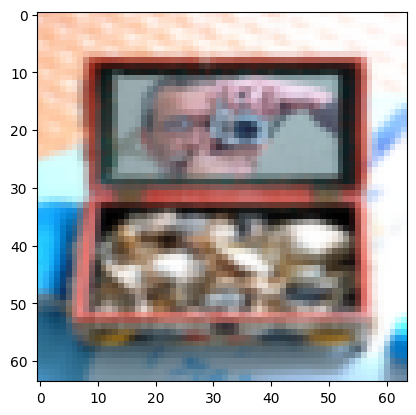

In [ ]:
# Example of a picture
index = 15
plt.imshow(train_x_orig[index])
print ("y = " + str(train_y[0,index]) + ". It's a " + classes[train_y[0,index]].decode("utf-8") +  " picture.")

In [ ]:
# Explore your dataset
m_train = train_x_orig.shape[0]
num_px = train_x_orig.shape[1]
m_test = test_x_orig.shape[0]

print ("Number of training examples: " + str(m_train))
print ("Number of testing examples: " + str(m_test))
print ("Each image is of size: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_x_orig shape: " + str(train_x_orig.shape))
print ("train_y shape: " + str(train_y.shape))
print ("test_x_orig shape: " + str(test_x_orig.shape))
print ("test_y shape: " + str(test_y.shape))

Number of training examples: 209
Number of testing examples: 50
Each image is of size: (64, 64, 3)
train_x_orig shape: (209, 64, 64, 3)
train_y shape: (1, 209)
test_x_orig shape: (50, 64, 64, 3)
test_y shape: (1, 50)


In [ ]:
# Reshape the training and test examples
train_x_flatten = train_x_orig.reshape(train_x_orig.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_x_orig.reshape(test_x_orig.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))


train_x's shape: (12288, 209)
test_x's shape: (12288, 50)


Architecture of the Model
Now that you are familiar with the dataset, it is time to build a deep neural network to distinguish cat images from non-cat images.

You will build two different models:
- A 2-layer neural network
- An L-layer deep neural network

You will then compare the performance of these models, and also try out different values for $L$.

Let's look at the two architectures.

### 2-layer neural network


<u>Detailed Architecture of figure 2</u>:
- The input is a (64,64,3) image which is flattened to a vector of size $(12288,1)$.
- The corresponding vector: $[x_0,x_1,...,x_{12287}]^T$ is then multiplied by the weight matrix $W^{[1]}$ of size $(n^{[1]}, 12288)$.
- You then add a bias term and take its relu to get the following vector: $[a_0^{[1]}, a_1^{[1]},..., a_{n^{[1]}-1}^{[1]}]^T$.
- You then repeat the same process.
- You multiply the resulting vector by $W^{[2]}$ and add your intercept (bias).
- Finally, you take the sigmoid of the result. If it is greater than 0.5, you classify it to be a cat.

###  L-layer deep neural network

It is hard to represent an L-layer deep neural network with the above representation. However, here is a simplified network representation:

<u>Detailed Architecture of figure 3</u>:
- The input is a (64,64,3) image which is flattened to a vector of size (12288,1).
- The corresponding vector: $[x_0,x_1,...,x_{12287}]^T$ is then multiplied by the weight matrix $W^{[1]}$ and then you add the intercept $b^{[1]}$. The result is called the linear unit.
- Next, you take the relu of the linear unit. This process could be repeated several times for each $(W^{[l]}, b^{[l]})$ depending on the model architecture.
- Finally, you take the sigmoid of the final linear unit. If it is greater than 0.5, you classify it to be a cat.

###  General methodology

As usual you will follow the Deep Learning methodology to build the model:
    1. Initialize parameters / Define hyperparameters
    2. Loop for num_iterations:
        a. Forward propagation
        b. Compute cost function
        c. Backward propagation
        d. Update parameters (using parameters, and grads from backprop)
    4. Use trained parameters to predict labels

Let's now implement those two models!

## 5 - Two-layer neural network

**Question**:  Use the helper functions you have implemented in the previous assignment to build a 2-layer neural network with the following structure: *LINEAR -> RELU -> LINEAR -> SIGMOID*. The functions you may need and their inputs are:
```python
def initialize_parameters(n_x, n_h, n_y):
    ...
    return parameters
def linear_activation_forward(A_prev, W, b, activation):
    ...
    return A, cache
def compute_cost(AL, Y):
    ...
    return cost
def linear_activation_backward(dA, cache, activation):
    ...
    return dA_prev, dW, db
def update_parameters(parameters, grads, learning_rate):
    ...
    return parameters
```

In [ ]:
### CONSTANTS DEFINING THE MODEL ####
n_x = 12288     # num_px * num_px * 3
n_h = 7
n_y = 1
layers_dims = (n_x, n_h, n_y)

In [ ]:

def two_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):

    np.random.seed(1)
    grads = {}
    costs = []                              # to keep track of the cost
    m = X.shape[1]                           # number of examples
    (n_x, n_h, n_y) = layers_dims

    # Initialize parameters dictionary, by calling one of the functions you'd previously implemented
    parameters = initialize_parameters(n_x, n_h, n_y)

    # Get W1, b1, W2 and b2 from the dictionary parameters.
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]

    # Loop (gradient descent)

    for i in range(0, num_iterations):

        # Forward propagation: LINEAR -> RELU -> LINEAR -> SIGMOID. Inputs: "X, W1, b1, W2, b2". Output: "A1, cache1, A2, cache2".
        A1, cache1 = linear_activation_forward(X, W1, b1, activation="relu")
        A2, cache2 = linear_activation_forward(A1, W2, b2, activation="sigmoid")

        # Compute cost
        cost = compute_cost(A2,Y)

        # Initializing backward propagation
        dA2 = - (np.divide(Y, A2) - np.divide(1 - Y, 1 - A2))

        # Backward propagation. Inputs: "dA2, cache2, cache1". Outputs: "dA1, dW2, db2; also dA0 (not used), dW1, db1".
        dA1, dW2, db2 = linear_activation_backward(dA2, cache2, activation="sigmoid")
        dA0, dW1, db1 = linear_activation_backward(dA1, cache1, activation="relu")

        # Set grads['dWl'] to dW1, grads['db1'] to db1, grads['dW2'] to dW2, grads['db2'] to db2
        grads['dW1'] = dW1
        grads['db1'] = db1
        grads['dW2'] = dW2
        grads['db2'] = db2

        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Retrieve W1, b1, W2, b2 from parameters
        W1 = parameters["W1"]
        b1 = parameters["b1"]
        W2 = parameters["W2"]
        b2 = parameters["b2"]

        # Print the cost every 100 training example
        if print_cost and i % 100 == 0:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if print_cost and i % 100 == 0:
            costs.append(cost)

    # plot the cost

    plt.plot(np.squeeze(costs))
    plt.ylabel('cost')
    plt.xlabel('iterations (per hundreds)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()

    return parameters

Cost after iteration 0: 0.6930497356599891
Cost after iteration 100: 0.6464320953428849
Cost after iteration 200: 0.6325140647912677
Cost after iteration 300: 0.6015024920354665
Cost after iteration 400: 0.5601966311605748
Cost after iteration 500: 0.515830477276473
Cost after iteration 600: 0.4754901313943325
Cost after iteration 700: 0.4339163151225749
Cost after iteration 800: 0.4007977536203886
Cost after iteration 900: 0.3580705011323798
Cost after iteration 1000: 0.3394281538366412
Cost after iteration 1100: 0.30527536361962637
Cost after iteration 1200: 0.27491377282130164
Cost after iteration 1300: 0.24681768210614843
Cost after iteration 1400: 0.19850735037466105
Cost after iteration 1500: 0.17448318112556643
Cost after iteration 1600: 0.17080762978096395
Cost after iteration 1700: 0.1130652456216472
Cost after iteration 1800: 0.09629426845937153
Cost after iteration 1900: 0.08342617959726865
Cost after iteration 2000: 0.07439078704319083
Cost after iteration 2100: 0.066307481

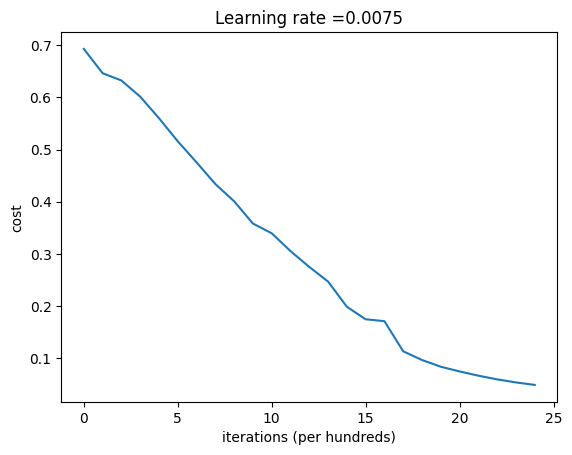

In [ ]:
parameters = two_layer_model(train_x, train_y, layers_dims = (n_x, n_h, n_y), num_iterations = 2500, print_cost=True)

### Lets define two functions to test the model

In [ ]:
def predict(X, y, parameters):

    m = X.shape[1]
    n = len(parameters) // 2 # number of layers in the neural network
    p = np.zeros((1,m))

    # Forward propagation
    probas, caches = L_model_forward(X, parameters)


    # convert probas to 0/1 predictions
    for i in range(0, probas.shape[1]):
        if probas[0,i] > 0.5:
            p[0,i] = 1
        else:
            p[0,i] = 0

    #print results
    #print ("predictions: " + str(p))
    #print ("true labels: " + str(y))
    print("Accuracy: "  + str(np.sum((p == y)/m)))

    return p

def print_mislabeled_images(classes, X, y, p):

    a = p + y
    mislabeled_indices = np.asarray(np.where(a == 1))
    plt.rcParams['figure.figsize'] = (40.0, 40.0) # set default size of plots
    num_images = len(mislabeled_indices[0])
    for i in range(num_images):
        index = mislabeled_indices[1][i]

        plt.subplot(2, num_images, i + 1)
        plt.imshow(X[:,index].reshape(64,64,3), interpolation='nearest')
        plt.axis('off')
        plt.title("Prediction: " + classes[int(p[0,index])].decode("utf-8") + " \n Class: " + classes[y[0,index]].decode("utf-8"))


In [ ]:
predictions_train = predict(train_x, train_y, parameters)
predictions_test = predict(test_x, test_y, parameters)

Accuracy: 0.9999999999999998
Accuracy: 0.72


## 6 - L-layer Neural Network

**Question**: Use the helper functions you have implemented previously to build an $L$-layer neural network with the following structure: *[LINEAR -> RELU]$\times$(L-1) -> LINEAR -> SIGMOID*. The functions you may need and their inputs are:
```python
def initialize_parameters_deep(layers_dims):
    ...
    return parameters
def L_model_forward(X, parameters):
    ...
    return AL, caches
def compute_cost(AL, Y):
    ...
    return cost
def L_model_backward(AL, Y, caches):
    ...
    return grads
def update_parameters(parameters, grads, learning_rate):
    ...
    return parameters
```

In [ ]:
### CONSTANTS ###
layers_dims = [12288, 20, 7, 5, 1] #  4-layer model

In [ ]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):#lr was 0.009

    np.random.seed(1)
    costs = []                         # keep track of cost

    # Parameters initialization. (≈ 1 line of code)
    parameters = initialize_parameters_deep(layers_dims)

    # Loop (gradient descent)
    for i in range(0, num_iterations):

        # Forward propagation: [LINEAR -> RELU]*(L-1) -> LINEAR -> SIGMOID.
        AL, caches = L_model_forward(X, parameters)

        # Compute cost.
        cost = compute_cost(AL,Y)

        # Backward propagation.
        grads = L_model_backward(AL, Y, caches)

        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the cost every 100 training example
        if print_cost and i % 100 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))
        if print_cost and i % 100 == 0:
            costs.append(cost)

    # plot the cost
    plt.plot(np.squeeze(costs))
    plt.ylabel('cost')
    plt.xlabel('iterations (per hundreds)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()

    return parameters

Cost after iteration 0: 0.693148
Cost after iteration 100: 0.678011
Cost after iteration 200: 0.667600
Cost after iteration 300: 0.660422
Cost after iteration 400: 0.655458
Cost after iteration 500: 0.652013
Cost after iteration 600: 0.649616
Cost after iteration 700: 0.647942
Cost after iteration 800: 0.646770
Cost after iteration 900: 0.645947
Cost after iteration 1000: 0.645368
Cost after iteration 1100: 0.644961
Cost after iteration 1200: 0.644673
Cost after iteration 1300: 0.644469
Cost after iteration 1400: 0.644325
Cost after iteration 1500: 0.644223
Cost after iteration 1600: 0.644151
Cost after iteration 1700: 0.644100
Cost after iteration 1800: 0.644063
Cost after iteration 1900: 0.644037
Cost after iteration 2000: 0.644019
Cost after iteration 2100: 0.644006
Cost after iteration 2200: 0.643997
Cost after iteration 2300: 0.643990
Cost after iteration 2400: 0.643985


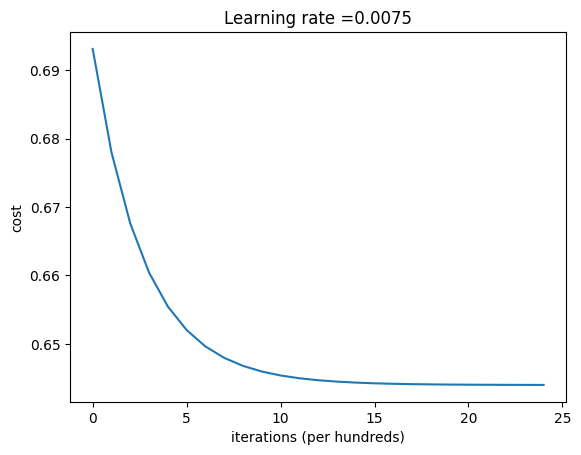

In [ ]:
parameters = L_layer_model(train_x, train_y, layers_dims, num_iterations = 2500, print_cost = True)

In [ ]:
pred_train=predictions_train = predict(train_x, train_y, parameters)
pred_test=predictions_test = predict(test_x, test_y, parameters)

Accuracy: 0.6555023923444976
Accuracy: 0.3400000000000001


##  7) Results Analysis

First, let's take a look at some images the L-layer model labeled incorrectly. This will show a few mislabeled images.

In [ ]:
print_mislabeled_images(classes, test_x, test_y, pred_test)

### How to use on new Image

In [ ]:
#my_image = "my_image.jpg" # change this to the name of your image file
#my_label_y = [1] # the true class of your image (1 -> cat, 0 -> non-cat)

#fname = "images/" + my_image
#image = np.array(ndimage.imread(fname, flatten=False))
#my_image = scipy.misc.imresize(image, size=(num_px,num_px)).reshape((num_px*num_px*3,1))
#my_image = my_image/255.
#my_predicted_image = predict(my_image, my_label_y, parameters)

#plt.imshow(image)
#print ("y = " + str(np.squeeze(my_predicted_image)) + ", your L-layer model predicts a \"" + classes[int(np.squeeze(my_predicted_image)),].decode("utf-8") +  "\" picture.")

## L Layer Model with Accuracy Tracking

In [ ]:
# L-Layer Neural Network Model
# This function is modified to store:
# 1. Cost at every 100 iterations
# 2. Training accuracy at every 100 iterations
# 3. Testing accuracy at every 100 iterations
# 4. Iteration numbers for plotting

def L_layer_model(X, Y, layers_dims,
                  learning_rate=0.0075,
                  num_iterations=2500,
                  print_cost=False):

    # Set random seed for reproducibility
    np.random.seed(1)

    # Lists to store cost and accuracy values
    costs = []
    train_acc = []
    test_acc = []
    iterations = []

    # Initialize weights and biases for all layers
    parameters = initialize_parameters_deep(layers_dims)

    # Start gradient descent
    for i in range(num_iterations):

        # -------------------------------
        # Step 1: Forward Propagation
        # -------------------------------
        AL, caches = L_model_forward(X, parameters)

        # -------------------------------
        # Step 2: Calculate Cost
        # -------------------------------
        cost = compute_cost(AL, Y)

        # -------------------------------
        # Step 3: Backward Propagation
        # -------------------------------
        grads = L_model_backward(AL, Y, caches)

        # -------------------------------
        # Step 4: Update Parameters
        # -------------------------------
        parameters = update_parameters(
            parameters,
            grads,
            learning_rate
        )

        # Store results after every 100 iterations
        if i % 100 == 0:

            # Make predictions on training data
            pred_train = predict(
                train_x,
                train_y,
                parameters
            )

            # Calculate training accuracy
            train_accuracy = np.mean(
                pred_train == train_y
            )

            # Make predictions on test data
            pred_test = predict(
                test_x,
                test_y,
                parameters
            )

            # Calculate test accuracy
            test_accuracy = np.mean(
                pred_test == test_y
            )

            # Store cost and accuracy values
            costs.append(cost)
            train_acc.append(train_accuracy)
            test_acc.append(test_accuracy)
            iterations.append(i)

            # Display results if print_cost is True
            if print_cost:
                print(
                    "Iteration {}: Cost = {:.4f}, "
                    "Train Accuracy = {:.2f}%, "
                    "Test Accuracy = {:.2f}%"
                    .format(
                        i,
                        cost,
                        train_accuracy * 100,
                        test_accuracy * 100
                    )
                )

    # Return trained parameters and recorded results
    return parameters, costs, train_acc, test_acc, iterations

## Train 2-Layer Neural Network

In [ ]:
# Define the architecture of the 2-layer neural network
# Input layer = 12288 neurons
# Hidden layer = 7 neurons
# Output layer = 1 neuron

layers_2 = [12288, 7, 1]

# Train the 2-layer neural network
# learning_rate = 0.0075
# num_iterations = 2500

parameters_2, cost_2, train_acc_2, test_acc_2, iter_2 = L_layer_model(
    train_x,
    train_y,
    layers_2,
    learning_rate=0.0075,
    num_iterations=2500,
    print_cost=True
)

##  Train 5-Layer Neural Network

In [ ]:
# Define the architecture of the 5-layer neural network
# Input layer = 12288 neurons
# Hidden Layer 1 = 20 neurons
# Hidden Layer 2 = 15 neurons
# Hidden Layer 3 = 10 neurons
# Hidden Layer 4 = 7 neurons
# Output layer = 1 neuron

layers_5 = [12288, 20, 15, 10, 7, 1]

# Train the 5-layer neural network
# Same learning rate and number of iterations
# so that the comparison with the 2-layer network is fair

parameters_5, cost_5, train_acc_5, test_acc_5, iter_5 = L_layer_model(
    train_x,
    train_y,
    layers_5,
    learning_rate=0.0075,
    num_iterations=2500,
    print_cost=True
)

##  Train 6-Layer Neural Network

In [ ]:
# Define the architecture of the 6-layer neural network
# Input layer = 12288 neurons
# Hidden Layer 1 = 20 neurons
# Hidden Layer 2 = 15 neurons
# Hidden Layer 3 = 10 neurons
# Hidden Layer 4 = 7 neurons
# Hidden Layer 5 = 5 neurons
# Output layer = 1 neuron

layers_6 = [12288, 20, 15, 10, 7, 5, 1]

# Train the 6-layer neural network
# Use the same learning rate and iterations
# for a fair comparison with 2-layer and 5-layer networks

parameters_6, cost_6, train_acc_6, test_acc_6, iter_6 = L_layer_model(
    train_x,
    train_y,
    layers_6,
    learning_rate=0.0075,
    num_iterations=2500,
    print_cost=True
)

## Accuracy Comparison: 2-Layer vs 5-Layer vs 6-Layer

In [ ]:
# Plot training accuracy for all three neural networks

plt.figure(figsize=(10, 6))

# Plot 2-layer network accuracy
plt.plot(
    iter_2,
    np.array(train_acc_2) * 100,
    label="2-Layer Network"
)

# Plot 5-layer network accuracy
plt.plot(
    iter_5,
    np.array(train_acc_5) * 100,
    label="5-Layer Network"
)

# Plot 6-layer network accuracy
plt.plot(
    iter_6,
    np.array(train_acc_6) * 100,
    label="6-Layer Network"
)

# Add graph labels and title
plt.xlabel("Iterations")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy vs Iterations")

# Display legend and grid
plt.legend()
plt.grid()

# Show the graph
plt.show()

## Test Accuracy Comparison: 2-Layer vs 5-Layer vs 6-Layer

In [ ]:
# Plot test accuracy for all three neural networks

plt.figure(figsize=(10, 6))

# Plot 2-layer network test accuracy
plt.plot(
    iter_2,
    np.array(test_acc_2) * 100,
    label="2-Layer Network"
)

# Plot 5-layer network test accuracy
plt.plot(
    iter_5,
    np.array(test_acc_5) * 100,
    label="5-Layer Network"
)

# Plot 6-layer network test accuracy
plt.plot(
    iter_6,
    np.array(test_acc_6) * 100,
    label="6-Layer Network"
)

# Add graph labels and title
plt.xlabel("Iterations")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy vs Iterations")

# Display legend and grid
plt.legend()
plt.grid()

# Show the graph
plt.show()

## Cost Function Comparison: 2-Layer vs 5-Layer vs 6-Layer

In [ ]:
# Plot the cost function for all three neural networks

plt.figure(figsize=(10, 6))

# Plot cost for 2-layer network
plt.plot(
    iter_2,
    cost_2,
    label="2-Layer Network"
)

# Plot cost for 5-layer network
plt.plot(
    iter_5,
    cost_5,
    label="5-Layer Network"
)

# Plot cost for 6-layer network
plt.plot(
    iter_6,
    cost_6,
    label="6-Layer Network"
)

# Add graph labels and title
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function vs Iterations")

# Display legend and grid
plt.legend()
plt.grid()

# Show the graph
plt.show()

##  Final Accuracy Comparison

In [ ]:
# Get the final training accuracy of each network

final_train_acc_2 = train_acc_2[-1] * 100
final_train_acc_5 = train_acc_5[-1] * 100
final_train_acc_6 = train_acc_6[-1] * 100

# Get the final test accuracy of each network

final_test_acc_2 = test_acc_2[-1] * 100
final_test_acc_5 = test_acc_5[-1] * 100
final_test_acc_6 = test_acc_6[-1] * 100

# Print the final accuracy results

print("Final Accuracy Comparison")
print("-------------------------")

print("2-Layer Network:")
print("Training Accuracy : {:.2f}%".format(final_train_acc_2))
print("Test Accuracy     : {:.2f}%".format(final_test_acc_2))

print("\n5-Layer Network:")
print("Training Accuracy : {:.2f}%".format(final_train_acc_5))
print("Test Accuracy     : {:.2f}%".format(final_test_acc_5))

print("\n6-Layer Network:")
print("Training Accuracy : {:.2f}%".format(final_train_acc_6))
print("Test Accuracy     : {:.2f}%".format(final_test_acc_6))

# Practical: 5-Layer Neural Network Classifier on CAT Dataset

## Regularization, Cross Validation and Variance Analysis

## Aim

To implement a 5-layer Neural Network classifier on the CAT dataset,
perform cross-validation to calculate average training and test accuracy,
and study the effect of different regularization techniques on model
variance and loss.

The following regularization techniques are implemented:

1. LASSO
2. RIDGE
3. Elastic Net
4. Dropout (0.1, 0.2, 0.3, 0.4, 0.5)
5. DropConnect (0.2, 0.4, 0.5)
6. Batch Normalization

## Objectives

1. To build a 5-layer Neural Network classifier.
2. To classify CAT and non-CAT images.
3. To perform 5-fold cross-validation.
4. To calculate average training accuracy.
5. To calculate average test accuracy.
6. To implement LASSO regularization.
7. To implement RIDGE regularization.
8. To implement Elastic Net regularization.
9. To study different Dropout rates.
10. To study different DropConnect rates.
11. To implement Batch Normalization.
12. To plot the loss function for each case.
13. To calculate and compare the final variance.

## Theory

A Neural Network is a machine learning model consisting of interconnected
layers of neurons. It learns patterns from the input data by adjusting
weights and biases during training.

In this practical, a 5-layer Neural Network is used for binary
classification of CAT and non-CAT images.

The architecture used is:

Input Layer → 128 → 64 → 32 → 16 → Output Layer

ReLU activation is used in the hidden layers and Sigmoid activation is
used in the output layer.

The Sigmoid function produces a value between 0 and 1, which is suitable
for binary classification.

Cross-validation is used to evaluate the model on different portions of
the dataset. In 5-fold cross-validation, the dataset is divided into
five parts and the model is trained and evaluated five times.

Regularization is used to reduce overfitting and variance.

The regularization techniques used are LASSO, RIDGE, Elastic Net,
Dropout, DropConnect and Batch Normalization.

### LASSO Regularization

LASSO uses L1 regularization. It adds a penalty based on the absolute
values of model weights. It can reduce unnecessary weights and helps
control overfitting.

### RIDGE Regularization

RIDGE uses L2 regularization. It adds a penalty based on the squared
values of model weights and helps keep the weights small.

### Elastic Net

Elastic Net combines L1 and L2 regularization. Therefore, it combines
the properties of LASSO and RIDGE.

### Dropout

Dropout randomly deactivates some neurons during training. This prevents
the network from depending too much on particular neurons and helps
reduce overfitting.

### DropConnect

DropConnect randomly removes some connections or weights between neurons
during training instead of removing complete neurons.

### Batch Normalization

Batch Normalization normalizes the activations of a neural network layer.
It can make training more stable and can help improve generalization.

## Dataset Description

The CAT dataset contains images belonging to two classes:

1. Cat
2. Non-Cat

Each image has dimensions of 64 × 64 × 3.

The images are flattened into a one-dimensional vector before being given
to the Neural Network.

Number of input features:

64 × 64 × 3 = 12288

The pixel values are normalized from the range 0–255 to the range 0–1.

#Implementation
###Import Libraries

In [ ]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l1, l2, l1_l2
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)


This cell imports all the libraries required for data loading,
visualization, Neural Network implementation, regularization and
cross-validation.

##Load Dataset

In [ ]:
train_dataset = h5py.File("train_catvnoncat.h5", "r")
test_dataset = h5py.File("test_catvnoncat.h5", "r")

train_x_orig = np.array(train_dataset["train_set_x"][:])
train_y_orig = np.array(train_dataset["train_set_y"][:])

test_x_orig = np.array(test_dataset["test_set_x"][:])
test_y_orig = np.array(test_dataset["test_set_y"][:])

classes = np.array(test_dataset["list_classes"][:])

print("Training data:", train_x_orig.shape)
print("Training labels:", train_y_orig.shape)

print("Testing data:", test_x_orig.shape)
print("Testing labels:", test_y_orig.shape)

print("Classes:", classes)

The CAT dataset is loaded from the H5 files. The images, labels and
class names are stored separately.

## Display Image

In [ ]:
index = 15

plt.figure(figsize=(4,4))
plt.imshow(train_x_orig[index])
plt.axis("off")

print(
    "Class:",
    classes[train_y_orig[index]].decode("utf-8")
)

plt.show()

This cell displays one image from the dataset to verify that the data
has been loaded correctly.

## Data Information

In [ ]:
print("Number of training examples:", train_x_orig.shape[0])
print("Number of testing examples:", test_x_orig.shape[0])
print("Image dimensions:", train_x_orig.shape[1:])
print("Number of classes:", len(classes))

##Flatten Images

In [ ]:
X_train = train_x_orig.reshape(train_x_orig.shape[0], -1)
X_test = test_x_orig.reshape(test_x_orig.shape[0], -1)

y_train = train_y_orig.astype(int)
y_test = test_y_orig.astype(int)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

The original image has dimensions 64 × 64 × 3.

It is converted into a vector containing:

64 × 64 × 3 = 12288

features.

## Normalize Data

In [ ]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Pixel values are divided by 255 so that they lie between 0 and 1.
Normalization helps the Neural Network train more effectively.

## 5-Layer Neural Network Architecture

The network contains five trainable layers:

Layer 1: 128 neurons + ReLU
Layer 2: 64 neurons + ReLU
Layer 3: 32 neurons + ReLU
Layer 4: 16 neurons + ReLU
Layer 5: 1 neuron + Sigmoid

Architecture:

12288 → 128 → 64 → 32 → 16 → 1

##Base Model

In [ ]:
def create_base_model(input_size):

    model = Sequential([

        Dense(
            128,
            activation="relu",
            input_shape=(input_size,)
        ),

        Dense(
            64,
            activation="relu"
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

ReLU is used in the hidden layers because it works well for deep
networks.

Sigmoid is used in the final layer because this is a binary
classification problem.

##Check Model

In [ ]:
model = create_base_model(X_train.shape[1])

model.summary()

## 5-Fold Cross Validation

The dataset is divided into five folds.

For every round:
- Four folds are used for training.
- One fold is used for testing/validation.

This process is repeated five times.

Finally, the average training accuracy, average test accuracy and
variance are calculated.

###Cross Validation Function

In [ ]:
def cross_validate_model(model_function, X, y,
                         epochs=30, batch_size=16):

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_accuracies = []
    test_accuracies = []
    histories = []

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(X, y), 1
    ):

        X_fold_train = X[train_idx]
        X_fold_test = X[test_idx]

        y_fold_train = y[train_idx]
        y_fold_test = y[test_idx]

        model = model_function(X.shape[1])

        history = model.fit(
            X_fold_train,
            y_fold_train,
            validation_data=(
                X_fold_test,
                y_fold_test
            ),
            epochs=epochs,
            batch_size=batch_size,
            verbose=0
        )

        train_loss, train_acc = model.evaluate(
            X_fold_train,
            y_fold_train,
            verbose=0
        )

        test_loss, test_acc = model.evaluate(
            X_fold_test,
            y_fold_test,
            verbose=0
        )

        train_accuracies.append(train_acc)
        test_accuracies.append(test_acc)
        histories.append(history)

        print(
            f"Fold {fold}: "
            f"Training Accuracy = {train_acc:.4f}, "
            f"Test Accuracy = {test_acc:.4f}"
        )

    avg_train_accuracy = np.mean(train_accuracies)
    avg_test_accuracy = np.mean(test_accuracies)

    variance = np.var(test_accuracies)

    return {
        "train_accuracy": avg_train_accuracy,
        "test_accuracy": avg_test_accuracy,
        "variance": variance,
        "train_accuracies": train_accuracies,
        "test_accuracies": test_accuracies,
        "histories": histories
    }

The function:

1. Creates 5 folds.
2. Trains the model five times.
3. Calculates training accuracy.
4. Calculates test accuracy.
5. Calculates average accuracy.
6. Calculates variance.
7. Saves loss values for plotting.



##Baseline Experiment

In [ ]:
baseline = cross_validate_model(
    create_base_model,
    X_train,
    y_train
)

print("\nBASELINE RESULTS")

print(
    "Average Training Accuracy:",
    baseline["train_accuracy"]
)

print(
    "Average Test Accuracy:",
    baseline["test_accuracy"]
)

print(
    "Final Variance:",
    baseline["variance"]
)

The baseline model is trained without any regularization. Its performance
is used for comparison with the regularized models.

### LASSO

In [ ]:
def create_lasso_model(input_size):

    reg = l1(0.001)

    model = Sequential([

        Dense(
            128,
            activation="relu",
            kernel_regularizer=reg,
            input_shape=(input_size,)
        ),

        Dense(
            64,
            activation="relu",
            kernel_regularizer=reg
        ),

        Dense(
            32,
            activation="relu",
            kernel_regularizer=reg
        ),

        Dense(
            16,
            activation="relu",
            kernel_regularizer=reg
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
lasso = cross_validate_model(
    create_lasso_model,
    X_train,
    y_train
)

print("\nLASSO")
print("Average Training Accuracy:",
      lasso["train_accuracy"])

print("Average Test Accuracy:",
      lasso["test_accuracy"])

print("Variance:",
      lasso["variance"])

LASSO = L1 regularization.

It adds a penalty to the weights and helps reduce unnecessary model complexity.

###RIDGE

In [ ]:
def create_ridge_model(input_size):

    reg = l2(0.001)

    model = Sequential([

        Dense(
            128,
            activation="relu",
            kernel_regularizer=reg,
            input_shape=(input_size,)
        ),

        Dense(64, activation="relu",
              kernel_regularizer=reg),

        Dense(32, activation="relu",
              kernel_regularizer=reg),

        Dense(16, activation="relu",
              kernel_regularizer=reg),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
ridge = cross_validate_model(
    create_ridge_model,
    X_train,
    y_train
)

print("\nRIDGE")
print("Average Training Accuracy:",
      ridge["train_accuracy"])

print("Average Test Accuracy:",
      ridge["test_accuracy"])

print("Variance:",
      ridge["variance"])

RIDGE = L2 regularization.

It discourages very large weights and helps control overfitting.

###Elastic Net

In [ ]:
def create_elastic_model(input_size):

    reg = l1_l2(
        l1=0.001,
        l2=0.001
    )

    model = Sequential([

        Dense(
            128,
            activation="relu",
            kernel_regularizer=reg,
            input_shape=(input_size,)
        ),

        Dense(64, activation="relu",
              kernel_regularizer=reg),

        Dense(32, activation="relu",
              kernel_regularizer=reg),

        Dense(16, activation="relu",
              kernel_regularizer=reg),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
elastic = cross_validate_model(
    create_elastic_model,
    X_train,
    y_train
)

print("\nELASTIC NET")

print("Average Training Accuracy:",
      elastic["train_accuracy"])

print("Average Test Accuracy:",
      elastic["test_accuracy"])

print("Variance:",
      elastic["variance"])

Elastic Net combines:

L1 + L2

###Dropout

In [ ]:
def create_dropout_model(input_size, rate):

    model = Sequential([

        Dense(
            128,
            activation="relu",
            input_shape=(input_size,)
        ),

        Dropout(rate),

        Dense(64, activation="relu"),

        Dropout(rate),

        Dense(32, activation="relu"),

        Dropout(rate),

        Dense(16, activation="relu"),

        Dropout(rate),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

###Dropout 0.1–0.5

In [ ]:
dropout_results = {}

for rate in [0.1, 0.2, 0.3, 0.4, 0.5]:

    print("\n----------------------")
    print("Dropout Rate:", rate)
    print("----------------------")

    result = cross_validate_model(
        lambda input_size, r=rate:
        create_dropout_model(input_size, r),
        X_train,
        y_train
    )

    dropout_results[rate] = result

    print(
        "Average Training Accuracy:",
        result["train_accuracy"]
    )

    print(
        "Average Test Accuracy:",
        result["test_accuracy"]
    )

    print(
        "Variance:",
        result["variance"]
    )

This automatically performs:

* Dropout 0.1
* Dropout 0.2
* Dropout 0.3
* Dropout 0.4
* Dropout 0.5

###DropConnect
Custom Layer

In [ ]:
class DropConnectDense(tf.keras.layers.Layer):

    def __init__(self, units, rate=0.2,
                 activation=None):

        super().__init__()

        self.units = units
        self.rate = rate
        self.activation = tf.keras.activations.get(
            activation
        )

    def build(self, input_shape):

        self.kernel = self.add_weight(
            name="kernel",
            shape=(input_shape[-1], self.units),
            initializer="glorot_uniform",
            trainable=True
        )

        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs, training=False):

        kernel = self.kernel

        if training:

            mask = tf.cast(
                tf.random.uniform(
                    tf.shape(kernel)
                ) >= self.rate,
                kernel.dtype
            )

            kernel = kernel * mask

        output = (
            tf.matmul(inputs, kernel)
            + self.bias
        )

        if self.activation:
            output = self.activation(output)

        return output

Dropout removes some neurons.

DropConnect removes some connections/weights.

##Create DropConnect Model

In [ ]:
def create_dropconnect_model(input_size, rate):

    model = Sequential([

        DropConnectDense(
            128,
            rate=rate,
            activation="relu"
        ),

        DropConnectDense(
            64,
            rate=rate,
            activation="relu"
        ),

        DropConnectDense(
            32,
            rate=rate,
            activation="relu"
        ),

        DropConnectDense(
            16,
            rate=rate,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.build((None, input_size))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

##DropConnect 0.2, 0.4, 0.5


In [ ]:
dropconnect_results = {}

for rate in [0.2, 0.4, 0.5]:

    print("\n----------------------")
    print("DropConnect Rate:", rate)
    print("----------------------")

    result = cross_validate_model(
        lambda input_size, r=rate:
        create_dropconnect_model(input_size, r),
        X_train,
        y_train
    )

    dropconnect_results[rate] = result

    print(
        "Average Training Accuracy:",
        result["train_accuracy"]
    )

    print(
        "Average Test Accuracy:",
        result["test_accuracy"]
    )

    print(
        "Variance:",
        result["variance"]
    )

##Batch Normalization

In [ ]:
def create_batchnorm_model(input_size):

    model = Sequential([

        Dense(
            128,
            activation="relu",
            input_shape=(input_size,)
        ),

        BatchNormalization(),

        Dense(64, activation="relu"),

        BatchNormalization(),

        Dense(32, activation="relu"),

        BatchNormalization(),

        Dense(16, activation="relu"),

        BatchNormalization(),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

##Lose Function

In [ ]:
def plot_loss(result, title):

    plt.figure(figsize=(8,5))

    for i, history in enumerate(
        result["histories"]
    ):

        plt.plot(
            history.history["val_loss"],
            label=f"Fold {i+1}"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation Loss")
    plt.title(title)

    plt.legend()
    plt.grid()

    plt.show()

##Baseline Loss

In [ ]:
plot_loss(
    baseline,
    "Baseline - Loss Function"
)

##LASSO Loss

In [ ]:
plot_loss(
    lasso,
    "LASSO - Loss Function"
)

##RIDGE Loss

In [ ]:
plot_loss(
    ridge,
    "RIDGE - Loss Function"
)

##Elastic Net Loss

In [ ]:
plot_loss(
    elastic,
    "ELASTIC NET - Loss Function"
)

##Dropout Loss

In [ ]:
for rate, result in dropout_results.items():

    plot_loss(
        result,
        f"Dropout {rate} - Loss Function"
    )

##DropConnect Loss

In [ ]:
for rate, result in dropout_results.items():

    plot_loss(
        result,
        f"Dropout {rate} - Loss Function"
    )

##Batch Normalization Loss

In [ ]:
plot_loss(
    batchnorm,
    "Batch Normalization - Loss Function"
)

##Final Results Table

In [ ]:
results = []

def add_result(name, result):

    results.append({

        "Method": name,

        "Average Training Accuracy":
            result["train_accuracy"],

        "Average Test Accuracy":
            result["test_accuracy"],

        "Final Variance":
            result["variance"]
    })


add_result("Baseline", baseline)

add_result("LASSO", lasso)

add_result("RIDGE", ridge)

add_result("Elastic Net", elastic)


for rate, result in dropout_results.items():

    add_result(
        f"Dropout {rate}",
        result
    )


for rate, result in dropconnect_results.items():

    add_result(
        f"DropConnect {rate}",
        result
    )


add_result(
    "Batch Normalization",
    batchnorm
)


results_df = pd.DataFrame(results)

results_df

##Convert Accuracy to Percentage

In [ ]:
results_percentage = results_df.copy()

results_percentage[
    "Average Training Accuracy"
] *= 100

results_percentage[
    "Average Test Accuracy"
] *= 100

results_percentage

##Variance Comparison

In [ ]:
plt.figure(figsize=(12,6))

plt.bar(
    results_df["Method"],
    results_df["Final Variance"]
)

plt.xlabel("Regularization Method")
plt.ylabel("Variance")
plt.title("Variance Comparison")

plt.xticks(rotation=60)

plt.grid(axis="y")

plt.show()

This graph compares the variance obtained using different
regularization techniques.

## Accuracy Comparison

In [ ]:
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(14,6))

plt.bar(
    x - width/2,
    results_df["Average Training Accuracy"],
    width,
    label="Training Accuracy"
)

plt.bar(
    x + width/2,
    results_df["Average Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.xlabel("Method")
plt.ylabel("Accuracy")

plt.title(
    "Training Accuracy vs Test Accuracy"
)

plt.xticks(
    x,
    results_df["Method"],
    rotation=60
)

plt.legend()
plt.grid(axis="y")

plt.show()

## Variance Calculation

Variance measures how much the test accuracy changes across the
different cross-validation folds.

Variance is calculated as:

Variance = (1/n) Σ(xᵢ - μ)²

where:

xᵢ = accuracy of each fold
μ = mean accuracy
n = number of folds

In Python we calculate it using:

np.var(test_accuracies)

## Loss Function

Binary Cross-Entropy is used as the loss function because the problem
contains two classes.

The binary cross-entropy loss is:

Loss = -[y log(ŷ) + (1-y) log(1-ŷ)]

where:

y = actual class
ŷ = predicted probability

## Result Analysis

The average training accuracy and test accuracy were calculated using
5-fold cross-validation.

The variance of the test accuracy was calculated for every model.

The loss curves were plotted to observe the learning behavior of the
different regularization techniques.

The results can be compared using the final results table and the
variance comparison graph.

The results show that regularization changes both the training and
test accuracy of the Neural Network. The variance also changes for
different regularization methods. The loss curves show how the model
learns during different epochs.

## Conclusion

A 5-layer Neural Network classifier was successfully implemented on the
CAT dataset.

5-fold cross-validation was performed to calculate the average training
accuracy and average test accuracy.

The following regularization techniques were implemented:

1. LASSO
2. RIDGE
3. Elastic Net
4. Dropout
5. DropConnect
6. Batch Normalization

Different Dropout rates (0.1, 0.2, 0.3, 0.4 and 0.5) and DropConnect
rates (0.2, 0.4 and 0.5) were tested.

Loss functions were plotted for all cases and the final variance was
calculated.

The experiment demonstrates how regularization techniques can be used
to control overfitting and variance in Neural Networks.